<a href="https://colab.research.google.com/github/osoliman/DSC110/blob/main/Instructor_copy/10_13_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv')

In [3]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


In [4]:
df['education'].unique()

array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

In [5]:
# Create a mapping dictionary (adjust based on your data dictionary)
education_map = {
    1.0: 'Less than 9th grade',
    2.0: '9-11th grade',
    3.0: 'High school grad',
    4.0: 'Some college or AA degree',
    5.0: 'College graduate',
    9.0: 'Do not know',
}
# Apply the mapping
df['education_label'] = df['education'].map(education_map).fillna('Missing')

In [6]:
df['education_label'].value_counts()

,count
education_label,
Missing,4139
College graduate,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Do not know,11


In [7]:
#Do it for diabetes
diabetes_map = {
    1.0: 'Diabetes',
    2.0: 'No Diabetes',
    3.0: 'Borderline',
    9.0: 'Do not know',
}
# Apply the mapping
df['diabetes_label'] = df['has_diabetes'].map(diabetes_map).fillna('Missing')

In [8]:
df['diabetes_label'].value_counts()

,count
diabetes_label,
No Diabetes,10371
Diabetes,1081
Borderline,284
Missing,193
Do not know,4


One numeric variable

In [9]:
# Calculate mean
df['systolic_bp'].mean()

# Calculate standard deviation
df['systolic_bp'].std()

# Or get both at once
df['systolic_bp'].describe()

,systolic_bp
count,7517.000000
mean,119.288546
std,18.561052
min,61.000000
25%,106.000000
50%,117.000000
75%,130.000000
max,232.000000


In [10]:
df['age'].median()

37.0

In [11]:
df['age'].quantile([0.25, 0.75])

,age
0.25,13.0
0.75,62.0


In [12]:
df['age'].mode()

,age
0,80.0


<Axes: >

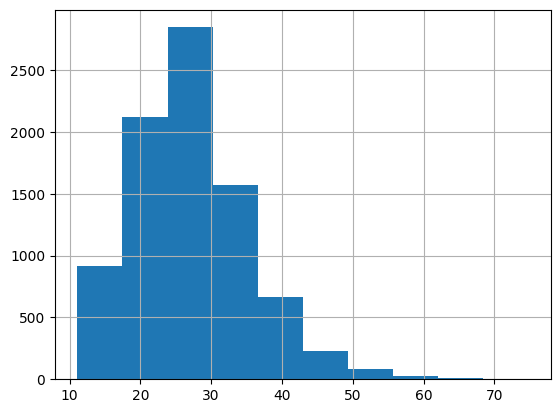

In [13]:
df['bmi'].hist()

Text(0, 0.5, 'Number of Respondents')

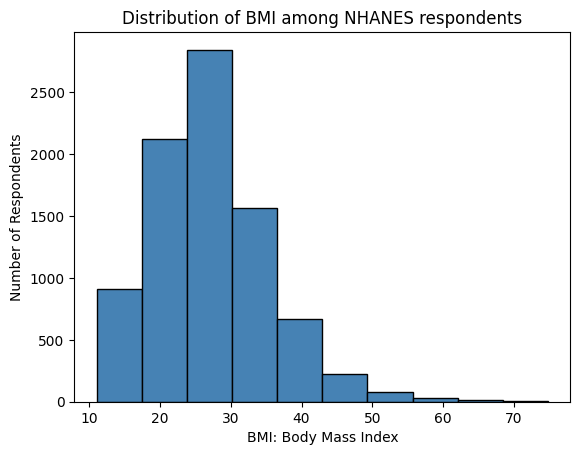

In [14]:
df['bmi'].hist(color = 'steelblue', edgecolor = 'black')
plt.title('Distribution of BMI among NHANES respondents')
plt.grid(False)
plt.xlabel('BMI: Body Mass Index')
plt.ylabel('Number of Respondents')

One categorical variable

In [15]:
df['education_label'].value_counts()

,count
education_label,
Missing,4139
College graduate,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Do not know,11


In [16]:
# With percentages
df['education_label'].value_counts(normalize=True) * 100

,proportion
education_label,
Missing,34.685326
College graduate,21.997821
Some college or AA degree,19.860890
High school grad,14.656834
9-11th grade,5.581161
Less than 9th grade,3.125786
Do not know,0.092181


<Axes: xlabel='education_label'>

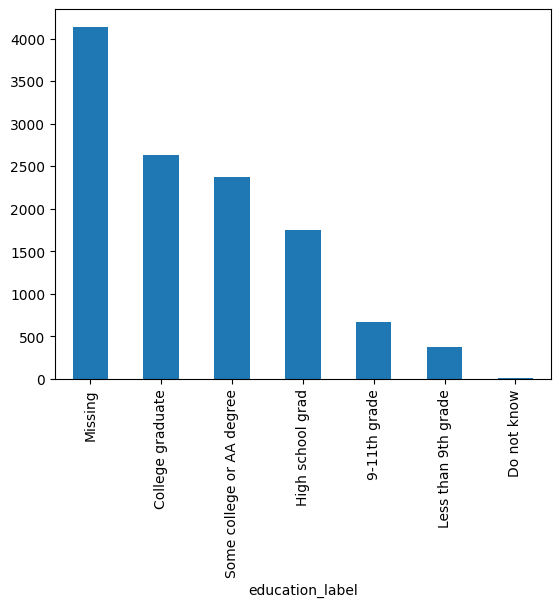

In [17]:
df['education_label'].value_counts().plot(kind='bar')

Two Numerical

In [18]:
df['fasting_glucose'].corr(df['hba1c'])

np.float64(0.8129616020662469)

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

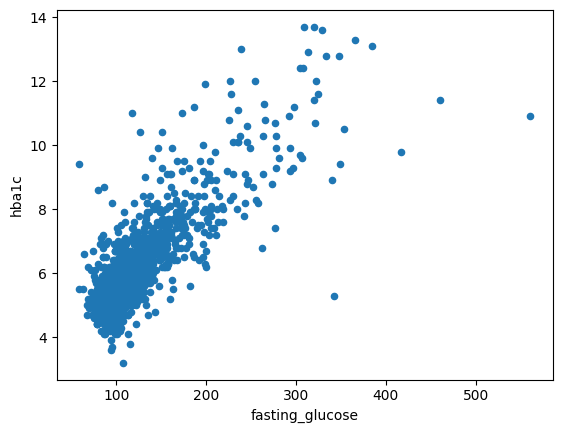

In [19]:
df.plot(x='fasting_glucose', y='hba1c', kind='scatter')

In [20]:
df_no_outliers = df[df['fasting_glucose']<300]

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

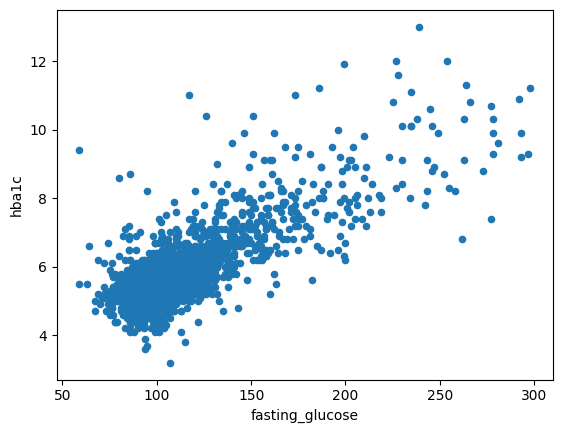

In [21]:
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')

Two categorical variables

In [22]:
df['bmi_category'] = pd.cut(df['bmi'],
                             bins=[0, 18.5, 25, 30, 100],
                             labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# Check it worked
df['bmi_category'].value_counts()

,count
bmi_category,
Obese,2666
Normal,2400
Overweight,2189
Underweight,1216


In [23]:
pd.crosstab(df['bmi_category'], df['has_diabetes'], normalize='index') * 100

has_diabetes,1.0,2.0,3.0,9.0
bmi_category,,,,
Underweight,0.328947,99.588816,0.000000,0.082237
Normal,4.541667,93.791667,1.625000,0.041667
Overweight,10.644130,86.158063,3.197807,0.000000
Obese,18.904726,76.594149,4.501125,0.000000


<Axes: xlabel='bmi_category'>

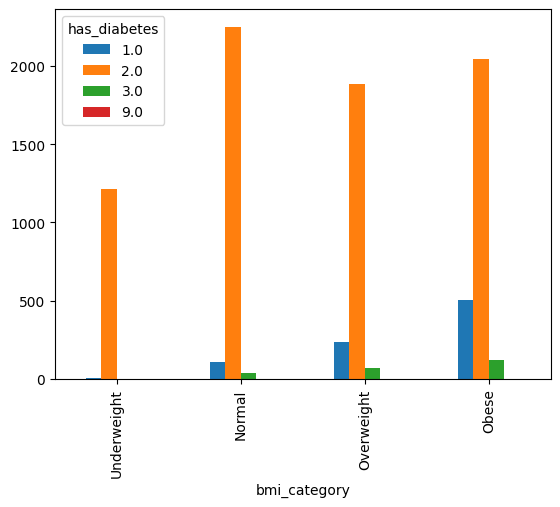

In [24]:
pd.crosstab(df['bmi_category'], df['has_diabetes']).plot(kind='bar')

<Axes: xlabel='bmi_category'>

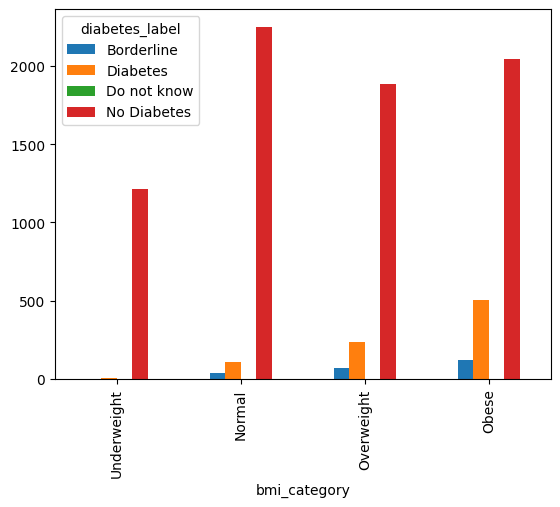

In [25]:
pd.crosstab(df['bmi_category'], df['diabetes_label']).plot(kind='bar')

<Axes: xlabel='diabetes_label'>

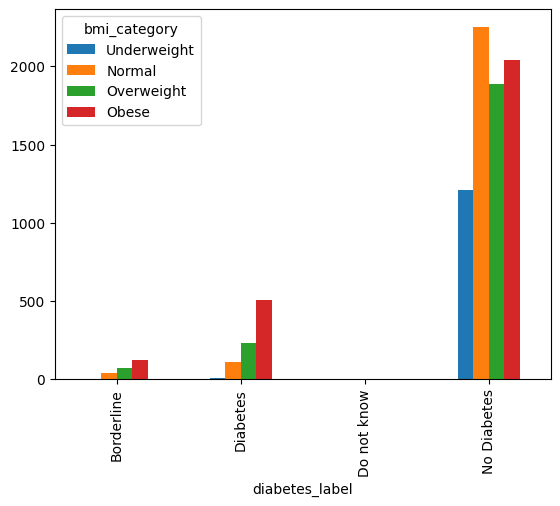

In [26]:
pd.crosstab(df['diabetes_label'], df['bmi_category']).plot(kind='bar')

One numerical and one categorical

In [27]:
df.groupby('diabetes_label')['bmi'].mean()

,bmi
diabetes_label,
Borderline,32.068559
Diabetes,32.981412
Do not know,19.250000
Missing,NaN
No Diabetes,26.439797


Text(0, 0.5, 'BMI')

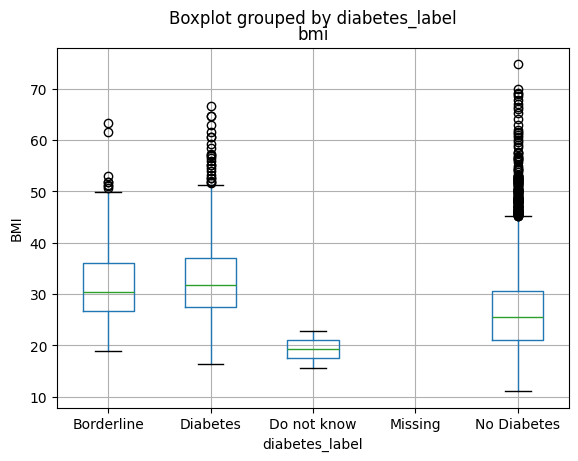

In [30]:
df.boxplot(column='bmi', by='diabetes_label')
plt.ylabel('BMI')

More

Text(0, 0.5, 'BMI (kg/m²)')

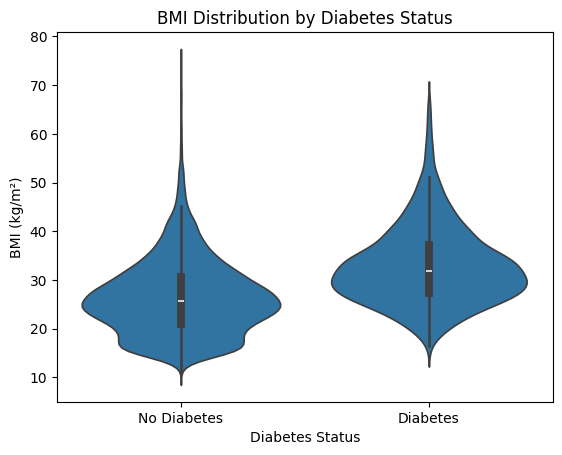

In [29]:
import seaborn as sns

# Filter to only Yes (1) and No (2) diabetes responses
df_diabetes = df[df['diabetes_label'].isin(['Diabetes', 'No Diabetes'])].copy()

# Create violin plot
sns.violinplot(data=df_diabetes, x='diabetes_label', y='bmi')
plt.title('BMI Distribution by Diabetes Status')
plt.xlabel('Diabetes Status')
plt.ylabel('BMI (kg/m²)')

Text(0.5, 1.0, 'Correlation Between Numeric Variables')

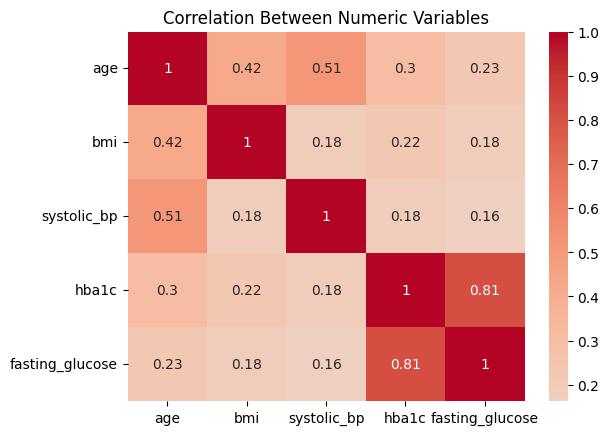

In [31]:
# Select only numeric columns
numeric_cols = df[['age', 'bmi', 'systolic_bp', 'hba1c', 'fasting_glucose']].corr()

sns.heatmap(numeric_cols, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Variables')

In [34]:
!pip install tableone

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.5 MB/s eta 0:00:00


In [35]:
import tableone

In [36]:
tableone.TableOne(df)

Missing            Overall
n                                                                         11933
id, mean (SD)                                              0  136344.0 (3444.9)
gender, n (%)              1.0                                      5575 (46.7)
                           2.0                                      6358 (53.3)
age, mean (SD)                                             0        38.3 (25.6)
race_ethnicity, n (%)      1.0                                       1117 (9.4)
                           2.0                                      1373 (11.5)
                           3.0                                      6217 (52.1)
                           4.0                                      1597 (13.4)
                           6.0                                        681 (5.7)
                           7.0                                        948 (7.9)
education, n (%)           1.0                                        373 (3.1)
                           2.0                                        666 (5.6)
                           3.0                                      1749 (14.7)
                           4.0                                      2370 (19.9)
                           5.0                                      2625 (22.0)
                           9.0                                         11 (0.1)
                           None                                     4139 (34.7)
bmi, mean (SD)                                          3462         27.2 (8.1)
height_cm, mean (SD)                                    3434       159.7 (19.9)
systolic_bp, mean (SD)                                  4416       119.3 (18.6)
has_diabetes, n (%)        1.0                                       1081 (9.1)
                           2.0                                     10371 (86.9)
                           3.0                                        284 (2.4)
                           9.0                                          4 (0.0)
                           None                                       193 (1.6)
hba1c, mean (SD)                                        5218          5.7 (1.1)
fasting_glucose, mean (SD)                              8261       107.9 (32.5)
education_label, n (%)     9-11th grade                               666 (5.6)
                           College graduate                         2625 (22.0)
                           Do not know                                 11 (0.1)
                           High school grad                         1749 (14.7)
                           Less than 9th grade                        373 (3.1)
                           Missing                                  4139 (34.7)
                           Some college or AA degree                2370 (19.9)
diabetes_label, n (%)      Borderline                                 284 (2.4)
                           Diabetes                                  1081 (9.1)
                           Do not know                                  4 (0.0)
                           Missing                                    193 (1.6)
                           No Diabetes                             10371 (86.9)
bmi_category, n (%)        Underweight                              1216 (10.2)
                           Normal                                   2400 (20.1)
                           Overweight                               2189 (18.3)
                           Obese                                    2666 (22.3)
                           None                                     3462 (29.0)

In [37]:
tableone.TableOne(df, show_histograms=True)

Missing            Overall Histogram
n                                                                         11933          
id, mean (SD)                                              0  136344.0 (3444.9)  █▇▇▇▇▇▇█
gender, n (%)              1.0                                      5575 (46.7)          
                           2.0                                      6358 (53.3)          
age, mean (SD)                                             0        38.3 (25.6)  █▇▃▄▄▄▆▆
race_ethnicity, n (%)      1.0                                       1117 (9.4)          
                           2.0                                      1373 (11.5)          
                           3.0                                      6217 (52.1)          
                           4.0                                      1597 (13.4)          
                           6.0                                        681 (5.7)          
                           7.0                                        948 (7.9)          
education, n (%)           1.0                                        373 (3.1)          
                           2.0                                        666 (5.6)          
                           3.0                                      1749 (14.7)          
                           4.0                                      2370 (19.9)          
                           5.0                                      2625 (22.0)          
                           9.0                                         11 (0.1)          
                           None                                     4139 (34.7)          
bmi, mean (SD)                                          3462         27.2 (8.1)  ▅▆█▆▃▂▁▁
height_cm, mean (SD)                                    3434       159.7 (19.9)  ▁▁▁▁▃█▇▃
systolic_bp, mean (SD)                                  4416       119.3 (18.6)  ▃▆█▅▃▂▁▁
has_diabetes, n (%)        1.0                                       1081 (9.1)          
                           2.0                                     10371 (86.9)          
                           3.0                                        284 (2.4)          
                           9.0                                          4 (0.0)          
                           None                                       193 (1.6)          
hba1c, mean (SD)                                        5218          5.7 (1.1)  ▄█▂▁▁▁▁▁
fasting_glucose, mean (SD)                              8261       107.9 (32.5)  █▅▁▁▁▁▁▁
education_label, n (%)     9-11th grade                               666 (5.6)          
                           College graduate                         2625 (22.0)          
                           Do not know                                 11 (0.1)          
                           High school grad                         1749 (14.7)          
                           Less than 9th grade                        373 (3.1)          
                           Missing                                  4139 (34.7)          
                           Some college or AA degree                2370 (19.9)          
diabetes_label, n (%)      Borderline                                 284 (2.4)          
                           Diabetes                                  1081 (9.1)          
                           Do not know                                  4 (0.0)          
                           Missing                                    193 (1.6)          
                           No Diabetes                             10371 (86.9)          
bmi_category, n (%)        Underweight                              1216 (10.2)          
                           Normal                                   2400 (20.1)          
                           Overweight                               2189 (18.3)          
                           Obese                                    2666 (22.3)          
   

In [38]:
tableone.TableOne(df, show_histograms=True, nonnormal=['age'])

Missing            Overall Histogram
n                                                                         11933          
id, mean (SD)                                              0  136344.0 (3444.9)  █▇▇▇▇▇▇█
gender, n (%)              1.0                                      5575 (46.7)          
                           2.0                                      6358 (53.3)          
age, median [Q1,Q3]                                        0   37.0 [13.0,62.0]  █▇▃▄▄▄▆▆
race_ethnicity, n (%)      1.0                                       1117 (9.4)          
                           2.0                                      1373 (11.5)          
                           3.0                                      6217 (52.1)          
                           4.0                                      1597 (13.4)          
                           6.0                                        681 (5.7)          
                           7.0                                        948 (7.9)          
education, n (%)           1.0                                        373 (3.1)          
                           2.0                                        666 (5.6)          
                           3.0                                      1749 (14.7)          
                           4.0                                      2370 (19.9)          
                           5.0                                      2625 (22.0)          
                           9.0                                         11 (0.1)          
                           None                                     4139 (34.7)          
bmi, mean (SD)                                          3462         27.2 (8.1)  ▅▆█▆▃▂▁▁
height_cm, mean (SD)                                    3434       159.7 (19.9)  ▁▁▁▁▃█▇▃
systolic_bp, mean (SD)                                  4416       119.3 (18.6)  ▃▆█▅▃▂▁▁
has_diabetes, n (%)        1.0                                       1081 (9.1)          
                           2.0                                     10371 (86.9)          
                           3.0                                        284 (2.4)          
                           9.0                                          4 (0.0)          
                           None                                       193 (1.6)          
hba1c, mean (SD)                                        5218          5.7 (1.1)  ▄█▂▁▁▁▁▁
fasting_glucose, mean (SD)                              8261       107.9 (32.5)  █▅▁▁▁▁▁▁
education_label, n (%)     9-11th grade                               666 (5.6)          
                           College graduate                         2625 (22.0)          
                           Do not know                                 11 (0.1)          
                           High school grad                         1749 (14.7)          
                           Less than 9th grade                        373 (3.1)          
                           Missing                                  4139 (34.7)          
                           Some college or AA degree                2370 (19.9)          
diabetes_label, n (%)      Borderline                                 284 (2.4)          
                           Diabetes                                  1081 (9.1)          
                           Do not know                                  4 (0.0)          
                           Missing                                    193 (1.6)          
                           No Diabetes                             10371 (86.9)          
bmi_category, n (%)        Underweight                              1216 (10.2)          
                           Normal                                   2400 (20.1)          
                           Overweight                               2189 (18.3)          
                           Obese                                    2666 (22.3)          
   